# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name: Afzaal  Roll No: ______


### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

### Data preparation helper
The lab says to put `pakistan_used_cars_clean.csv` next to the notebook. If you only have the raw `pakistan_used_cars.csv`, this cell builds the clean file (removes repeated ads, turns `Rs 435,000` into a number, drops impossible mileages above 260,000 km, adds `Price_lakh` and `Age = 2020 - Year`). If the clean file already exists it does nothing.

In [74]:
# Helper (not part of the graded tasks): builds pakistan_used_cars_clean.csv from the raw
# pakistan_used_cars.csv ONLY if the clean file is not already next to this notebook.
import os
if not os.path.exists("pakistan_used_cars_clean.csv"):
    raw = pd.read_csv("pakistan_used_cars.csv").drop_duplicates()          # remove repeated ads
    raw["Price"] = pd.to_numeric(raw["Price"].astype(str)
                                 .str.replace("Rs", "").str.replace(",", "").str.strip(),
                                 errors="coerce")                           # "Rs 435,000" -> 435000
    raw = raw[raw["KMs Driven"] < 260000]                                   # drop impossible mileages
    raw["Price_lakh"] = raw["Price"] / 100000                               # 1 lakh = 100,000 rupees
    raw["Age"] = 2020 - raw["Year"]                                         # age in 2020
    raw.to_csv("pakistan_used_cars_clean.csv", index=False)
print("clean file ready:", os.path.exists("pakistan_used_cars_clean.csv"))

clean file ready: True


## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).


T1a: shape of the whole file: (20009, 11)
T1b: shape of gli: (796, 11)
T1c: summary statistics
          Age  Price_lakh
count  796.00      796.00
mean     6.43       16.62
std      3.10        3.99
min      2.00        6.54
25%      4.00       13.50
50%      6.00       16.50
75%      9.00       19.50
max     15.00       30.00
T1d: correlation Age vs Price_lakh = -0.896


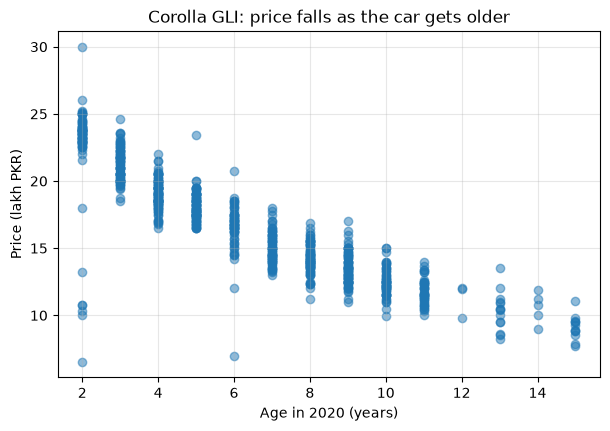

In [75]:
# T1: Load and explore
# (a) load and print shape
df = pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a: shape of the whole file:", df.shape)

# (b) keep Corolla GLI, Cash ads, Year 2005-2018, Price_lakh 5-40
gli = df[(df["Model"] == "Corolla GLI")
         & (df["Transaction Type"] == "Cash")
         & (df["Year"].between(2005, 2018))
         & (df["Price_lakh"].between(5, 40))].copy()
print("T1b: shape of gli:", gli.shape)

# (c) summary statistics
print("T1c: summary statistics")
print(gli[["Age", "Price_lakh"]].describe().round(2))

# (d) correlation
corr = gli["Age"].corr(gli["Price_lakh"])
print("T1d: correlation Age vs Price_lakh =", round(corr, 3))

# (e) scatter plot
plt.figure(figsize=(7, 4.5))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.5, color="tab:blue")
plt.title("Corolla GLI: price falls as the car gets older")
plt.xlabel("Age in 2020 (years)")
plt.ylabel("Price (lakh PKR)")
plt.grid(alpha=0.3)
plt.show()

**Answer (T1):** Yes, a straight line is a sensible model. (d) The correlation between Age and Price_lakh is **-0.896**, which is strong and negative: older cars are cheaper. (e) The scatter plot shows the points falling along one downward band with no wild curve, so a line fits the main pattern well. Two cautions: the band bends very slightly (it falls a little faster in the early years than in the later ones), and a few points sit far below the band (for example a 2-year-old car at about 6.5 lakh), which look like wrong prices.

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.


In [76]:
# T2: Features, target and split
# (a) X must be 2-D (double brackets), y is 1-D
X = gli[["Age"]]
y = gli["Price_lakh"]
print("T2a: X shape:", X.shape, "| y shape:", y.shape)

# (b) 80 / 20 split, always before fitting anything
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("T2b: X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| y_train:", y_train.shape, "| y_test:", y_test.shape)

T2a: X shape: (796, 1) | y shape: (796,)
T2b: X_train: (636, 1) | X_test: (160, 1) | y_train: (636,) | y_test: (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.


In [77]:
# T3: Least squares with NumPy (training data only)
x_tr = X_train["Age"].to_numpy()
y_tr = y_train.to_numpy()

# (a) means
x_bar = np.mean(x_tr)
y_bar = np.mean(y_tr)
print("T3a: x_bar =", round(x_bar, 3), "years | y_bar =", round(y_bar, 3), "lakh")

# (b) slope and intercept from the formulas
b1 = np.sum((x_tr - x_bar) * (y_tr - y_bar)) / np.sum((x_tr - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print("T3b: slope b1 =", round(b1, 4), "lakh/year")
print("T3b: intercept b0 =", round(b0, 4), "lakh")
print("T3b: line: price = %.3f + (%.3f) * age" % (b0, b1))

T3a: x_bar = 6.412 years | y_bar = 16.616 lakh
T3b: slope b1 = -1.1521 lakh/year
T3b: intercept b0 = 24.0035 lakh
T3b: line: price = 24.003 + (-1.152) * age


**Answer (T3c):**
- **b₁ = -1.152 lakh per year (slope):** every extra year of age lowers the expected price of a Corolla GLI by about **1.15 lakh rupees (about Rs 115,000)**. The sign is negative because older cars are cheaper.
- **b₀ = 24.00 lakh (intercept):** the price the line gives at age 0, i.e. a brand-new car. About 24 lakh is a believable price for a new-ish GLI, so here the intercept has a real meaning, but it is outside the data we actually saw (ages 2 to 15) and should only be read as the line's starting point.

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.


In [78]:
# T4: Train with scikit-learn
# (a) create, fit on TRAIN only, show the parameters
model = LinearRegression()
model.fit(X_train, y_train)
print("T4a: slope (coef_) =", round(model.coef_[0], 4))
print("T4a: intercept (intercept_) =", round(model.intercept_, 4))

# (b) are they the same as the NumPy values?
print("T4b: slopes equal?    ", np.isclose(model.coef_[0], b1))
print("T4b: intercepts equal?", np.isclose(model.intercept_, b0))

T4a: slope (coef_) = -1.1521
T4a: intercept (intercept_) = 24.0035
T4b: slopes equal?     True
T4b: intercepts equal? True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.


In [79]:
# T5: Evaluate on the test set
# (a) predictions and the four metrics by formula
y_pred = model.predict(X_test)
y_te = y_test.to_numpy()
errors = y_te - y_pred

mae  = np.mean(np.abs(errors))
mse  = np.mean(errors ** 2)
rmse = np.sqrt(mse)
sse  = np.sum(errors ** 2)
sst  = np.sum((y_te - np.mean(y_te)) ** 2)
r2   = 1 - sse / sst
print("T5a (formulas): MAE = %.3f lakh | MSE = %.3f lakh^2 | RMSE = %.3f lakh | R2 = %.3f" % (mae, mse, rmse, r2))

# (b) check with sklearn.metrics
print("T5b (sklearn):  MAE = %.3f | MSE = %.3f | R2 = %.3f" % (
      mean_absolute_error(y_te, y_pred), mean_squared_error(y_te, y_pred), r2_score(y_te, y_pred)))
print("T5b: formulas match sklearn?",
      np.isclose(mae, mean_absolute_error(y_te, y_pred)),
      np.isclose(mse, mean_squared_error(y_te, y_pred)),
      np.isclose(r2, r2_score(y_te, y_pred)))

# (c) train R2 vs test R2
train_r2 = r2_score(y_train, model.predict(X_train))
test_r2 = r2_score(y_test, y_pred)
print("T5c: train R2 = %.3f | test R2 = %.3f | gap = %.3f" % (train_r2, test_r2, train_r2 - test_r2))

# (d) baseline: always predict the TRAINING mean
base_pred = np.full(len(y_te), y_train.mean())
base_mae = mean_absolute_error(y_te, base_pred)
base_r2 = r2_score(y_te, base_pred)
print("T5d: baseline (train mean = %.2f lakh): MAE = %.3f | R2 = %.3f" % (y_train.mean(), base_mae, base_r2))
print("T5d: model MAE is %.0f%% lower than the baseline MAE" % (100 * (1 - mae / base_mae)))

T5a (formulas): MAE = 1.160 lakh | MSE = 2.716 lakh^2 | RMSE = 1.648 lakh | R2 = 0.831
T5b (sklearn):  MAE = 1.160 | MSE = 2.716 | R2 = 0.831
T5b: formulas match sklearn? True True True
T5c: train R2 = 0.795 | test R2 = 0.831 | gap = -0.036
T5d: baseline (train mean = 16.62 lakh): MAE = 3.445 | R2 = -0.000
T5d: model MAE is 66% lower than the baseline MAE


**Answer (T5):**
- **MAE = 1.16 lakh:** on average the model's price is wrong by about **1.16 lakh rupees (about Rs 116,000)** on ads it has never seen. It is in the same unit as the price, so it is the easiest number to explain.
- **R² = 0.83:** age alone explains about **83 %** of the differences in price between the test cars. R² is *not* "83 % accurate"; it says how much better the line is than always guessing the average (1 = perfect, 0 = no better than the mean).
- **Overfitting?** No. Train R² (0.795) is slightly *lower* than test R² (0.831), so the model did not memorise the training ads. The small gap is just luck in which ads landed in the test set.
- **Baseline:** always guessing the training mean (16.6 lakh) gives MAE = 3.45 lakh and R² ≈ 0. Our model's MAE of 1.16 is about **66 % lower** (roughly 3 times smaller), so using age is clearly much better than guessing.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?


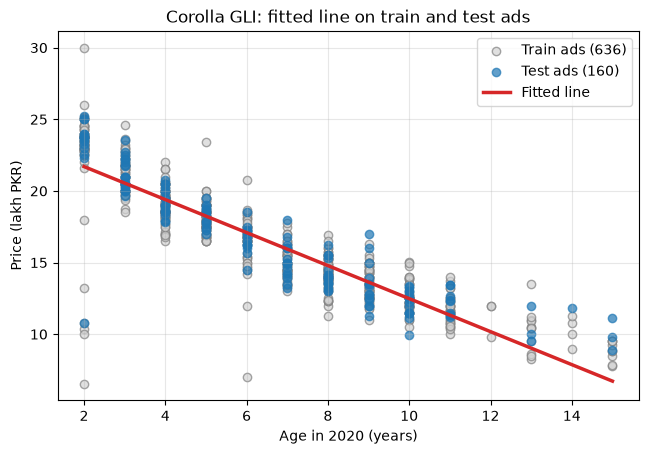

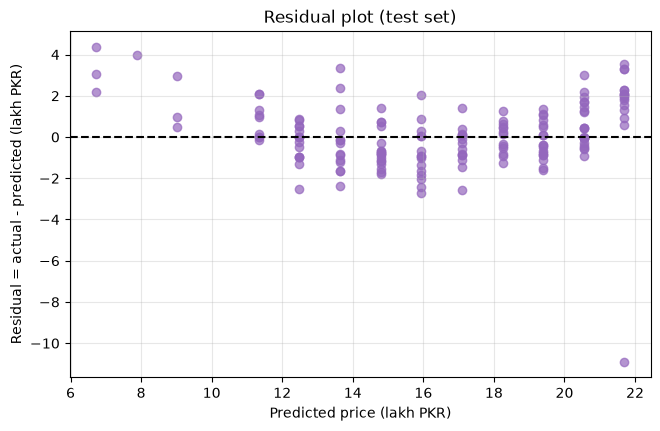

T6c: five test ads with the largest absolute error
         Year  KMs Driven Registered City  Actual_lakh  Predicted_lakh  Error_lakh
18381  2018.0         1.0             NaN        10.80           21.70      -10.90
14518  2005.0     64000.0         Karachi        11.10            6.72        4.38
19814  2006.0    220000.0       Islamabad        11.85            7.87        3.98
16827  2018.0      9000.0          Lahore        25.25           21.70        3.55
16217  2011.0    150000.0       Islamabad        17.00           13.63        3.37


In [80]:
# T6: Visualise the line and the errors
# (a) train (grey), test and the fitted line in one plot
plt.figure(figsize=(7.5, 4.8))
plt.scatter(X_train["Age"], y_train, color="lightgrey", edgecolor="grey", alpha=0.7, label="Train ads (636)")
plt.scatter(X_test["Age"], y_test, color="tab:blue", alpha=0.7, label="Test ads (160)")
ages = pd.DataFrame({"Age": np.linspace(X["Age"].min(), X["Age"].max(), 100)})
plt.plot(ages["Age"], model.predict(ages), color="tab:red", linewidth=2.5, label="Fitted line")
plt.title("Corolla GLI: fitted line on train and test ads")
plt.xlabel("Age in 2020 (years)")
plt.ylabel("Price (lakh PKR)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# (b) residual plot for the test set
residuals = y_te - y_pred
plt.figure(figsize=(7.5, 4.5))
plt.scatter(y_pred, residuals, alpha=0.7, color="tab:purple")
plt.axhline(0, color="black", linestyle="--")
plt.title("Residual plot (test set)")
plt.xlabel("Predicted price (lakh PKR)")
plt.ylabel("Residual = actual - predicted (lakh PKR)")
plt.grid(alpha=0.3)
plt.show()

# (c) five largest absolute errors
worst = gli.loc[X_test.index, ["Year", "KMs Driven", "Registered City"]].copy()
worst["Actual_lakh"] = y_test
worst["Predicted_lakh"] = y_pred
worst["Error_lakh"] = worst["Actual_lakh"] - worst["Predicted_lakh"]
worst = worst.reindex(worst["Error_lakh"].abs().sort_values(ascending=False).index).head(5)
print("T6c: five test ads with the largest absolute error")
print(worst.round(2).to_string())

**Answer (T6):**
- **Residual plot:** it is mostly a random cloud around zero with **no funnel** (the spread does not grow with the price). There is only a **very mild curve**: the residuals are slightly positive at the two ends (the newest and the oldest cars) and slightly negative in the middle, which means the real relationship bends a little. This is small, so a straight line is still a fair model.
- **Largest errors:** the biggest one is a 2018 car listed at **10.8 lakh** while the model says 21.7 (11 lakh too low). That ad has `KMs Driven = 1` and no city, so it is a **data mistake** (wrong price or a down payment), not a model mistake. The next ones (a 2005 car at 11.1 lakh, a 2006 car at 11.85 lakh with 220,000 km, a 2018 car at 25.25 lakh, a 2011 car at 17 lakh) are real differences that age alone cannot see (condition, mileage, trim, seller), so those are **limits of the model**, not errors in the data.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?


In [81]:
# T7: Use the model
# (a) 2018, 2015 and 2010 (age = 2020 - year)
years = [2018, 2015, 2010]
new_cars = pd.DataFrame({"Age": [2020 - yr for yr in years]})
for yr, price in zip(years, model.predict(new_cars)):
    print("T7a: %d Corolla GLI (age %d) -> %.2f lakh" % (yr, 2020 - yr, price))

# (b) extrapolation: a 1995 car (age 25) is far outside the training range
print("T7b: age range the model saw: %d to %d years" % (X["Age"].min(), X["Age"].max()))
print("T7b: 1995 Corolla GLI (age 25) -> %.2f lakh" % model.predict(pd.DataFrame({"Age": [25]}))[0])

T7a: 2018 Corolla GLI (age 2) -> 21.70 lakh
T7a: 2015 Corolla GLI (age 5) -> 18.24 lakh
T7a: 2010 Corolla GLI (age 10) -> 12.48 lakh
T7b: age range the model saw: 2 to 15 years
T7b: 1995 Corolla GLI (age 25) -> -4.80 lakh


**Answer (T7b):** No, **-4.80 lakh is not believable**: a car can never have a negative price. The model was trained only on cars aged 2 to 15 years. Age 25 is far outside this range, and a straight line keeps going down forever, so it gives nonsense. This is called **extrapolation**; we should only predict inside the range the model has seen (2 to 15 years). A real 1995 Corolla's price would depend on other things (like being a collector's car), not on this line.

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.


**Reflection (T8):** I loaded the Corolla GLI cash ads and filtered them to 796 ads, checked the scatter plot and the correlation (-0.896), chose Age as X (2-D) and Price_lakh as y, and **split the data 80/20 before doing anything else**. Then I found b₀ and b₁ by least squares in NumPy on the training data, confirmed that scikit-learn's `LinearRegression` gives the same numbers, and finally evaluated on the test set with MAE, MSE, RMSE and R², compared with a baseline, and looked at the residuals. The model must be judged on the **test set** because the training ads were used to build the line; scoring on them is like grading a student on the questions they already practised, and it hides overfitting. To a car buyer I would say the **MAE: "the price from this line is usually off by about 1.2 lakh rupees"**, because it is in rupees and easy to understand, while R² is not an accuracy and means little to a buyer. One limitation of using age alone is that two cars of the same age can have very different prices because of mileage, condition, city and trim, so the model cannot see those differences (and it cannot be trusted for ages outside 2 to 15 years).